#0. 라이브러리 *불러오기*

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, roc_auc_score, mean_squared_error, r2_score
)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from xgboost import XGBClassifier, XGBRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report
import shap
import warnings
warnings.filterwarnings("ignore")

In [2]:
import pandas as pd
import numpy as np

from google.colab import files
uploaded = files.upload()  # 파일 선택창에서 sample.xlsx 업로드

Saving model_dataset_essential.csv to model_dataset_essential (2).csv


In [3]:
df = pd.read_csv("model_dataset_essential.csv")
print("데이터 크기:", df.shape)
df.head()

데이터 크기: (1200, 23)


,hadm_id,subject_id,admittime,dischtime,deathtime,dod,death_type,death_binary,hospital_death,los_hours,...,admission_type,Hematocrit_51221_merged,Hemoglobin_51222,Creatinine_50912_merged,RDW_51277,White_Blood_Cells_51301_merged,Urea_Nitrogen_51006_merged,Potassium_50971_merged,Sodium_50983_merged,Glucose_50931
0,29686042,12823948,2138-08-07 22:17:00,2138-08-08 13:30:00,NaN,NaN,alive,0,0,15.216667,...,EU OBSERVATION,44.3,15.0,0.5,12.6,10.7,5.0,3.6,135.0,97.0
1,23654078,17275231,2147-03-19 18:47:00,2147-03-23 12:55:00,NaN,NaN,alive,0,0,90.133333,...,EW EMER.,38.6,14.0,1.1,12.9,7.5,14.0,3.8,137.0,112.0
2,28963677,18666150,2126-08-04 10:54:00,2126-08-05 18:06:00,NaN,NaN,alive,0,0,31.200000,...,DIRECT OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,24798258,16232868,2147-12-06 01:42:00,2147-12-09 20:15:00,NaN,NaN,alive,0,0,90.550000,...,EU OBSERVATION,29.8,9.8,4.3,15.2,5.7,74.0,3.4,137.0,89.0
4,25574544,15077620,2142-03-03 13:09:00,2142-03-05 15:00:00,NaN,NaN,alive,0,0,49.850000,...,EU OBSERVATION,34.5,12.0,0.6,13.8,9.8,8.0,3.8,141.0,95.0


#데이터 구조, 변수명, 결측치, 데이터 타입 확인



In [4]:
# --------------------------------------------
# 📌 데이터 구조, 변수명, 결측치, 데이터 타입 확인
# --------------------------------------------

print("\n===== 데이터 기본 구조(df.info()) =====")
df.info()

print("\n===== 데이터 컬럼명 리스트 =====")
print(df.columns.tolist())

print("\n===== 데이터 상위 5행(df.head()) =====")
display(df.head())

print("\n===== 기술통계(df.describe()) =====")
display(df.describe(include='all'))

print("\n===== 변수별 결측치 수 =====")
print(df.isnull().sum())

print("\n===== 숫자형 / 범주형 변수 분리 =====")
num_cols = df.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = df.select_dtypes(include=['object','category']).columns.tolist()

print("● 숫자형 변수 개수:", len(num_cols))
print(num_cols)

print("\n● 범주형 변수 개수:", len(cat_cols))
print(cat_cols)


===== 데이터 기본 구조(df.info()) =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hadm_id                         1200 non-null   int64  
 1   subject_id                      1200 non-null   int64  
 2   admittime                       1200 non-null   object 
 3   dischtime                       1200 non-null   object 
 4   deathtime                       299 non-null    object 
 5   dod                             600 non-null    object 
 6   death_type                      1200 non-null   object 
 7   death_binary                    1200 non-null   int64  
 8   hospital_death                  1200 non-null   int64  
 9   los_hours                       1200 non-null   float64
 10  los_days                        1200 non-null   float64
 11  age                             1200 non-null   int64  
 12  

,hadm_id,subject_id,admittime,dischtime,deathtime,dod,death_type,death_binary,hospital_death,los_hours,...,admission_type,Hematocrit_51221_merged,Hemoglobin_51222,Creatinine_50912_merged,RDW_51277,White_Blood_Cells_51301_merged,Urea_Nitrogen_51006_merged,Potassium_50971_merged,Sodium_50983_merged,Glucose_50931
0,29686042,12823948,2138-08-07 22:17:00,2138-08-08 13:30:00,NaN,NaN,alive,0,0,15.216667,...,EU OBSERVATION,44.3,15.0,0.5,12.6,10.7,5.0,3.6,135.0,97.0
1,23654078,17275231,2147-03-19 18:47:00,2147-03-23 12:55:00,NaN,NaN,alive,0,0,90.133333,...,EW EMER.,38.6,14.0,1.1,12.9,7.5,14.0,3.8,137.0,112.0
2,28963677,18666150,2126-08-04 10:54:00,2126-08-05 18:06:00,NaN,NaN,alive,0,0,31.200000,...,DIRECT OBSERVATION,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,24798258,16232868,2147-12-06 01:42:00,2147-12-09 20:15:00,NaN,NaN,alive,0,0,90.550000,...,EU OBSERVATION,29.8,9.8,4.3,15.2,5.7,74.0,3.4,137.0,89.0
4,25574544,15077620,2142-03-03 13:09:00,2142-03-05 15:00:00,NaN,NaN,alive,0,0,49.850000,...,EU OBSERVATION,34.5,12.0,0.6,13.8,9.8,8.0,3.8,141.0,95.0



===== 기술통계(df.describe()) =====


,hadm_id,subject_id,admittime,dischtime,deathtime,dod,death_type,death_binary,hospital_death,los_hours,...,admission_type,Hematocrit_51221_merged,Hemoglobin_51222,Creatinine_50912_merged,RDW_51277,White_Blood_Cells_51301_merged,Urea_Nitrogen_51006_merged,Potassium_50971_merged,Sodium_50983_merged,Glucose_50931
count,1.200000e+03,1.200000e+03,1200,1200,299,600,1200,1200.000000,1200.000000,1200.000000,...,1200,1148.000000,1143.000000,1126.000000,1141.000000,1142.000000,1122.000000,1114.000000,1112.000000,1099.000000
unique,NaN,NaN,1200,1200,299,569,3,NaN,NaN,NaN,...,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,2174-04-20 23:19:00,2174-04-26 16:30:00,2118-01-13 14:31:00,2144-12-31,alive,NaN,NaN,NaN,...,EW EMER.,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,1,1,1,2,600,NaN,NaN,NaN,...,542,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2.490751e+07,1.488715e+07,NaN,NaN,NaN,NaN,NaN,0.500000,0.250000,153.341194,...,NaN,34.664634,11.369554,1.544583,15.219720,10.067688,26.741533,4.294434,138.012590,140.371247
std,2.868541e+06,2.817484e+06,NaN,NaN,NaN,NaN,NaN,0.500208,0.433193,251.520080,...,NaN,6.607177,2.363855,1.748747,2.438994,7.769935,21.637700,0.762536,4.681371,76.762167
min,2.000346e+07,1.000582e+07,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,0.000000,...,NaN,10.500000,2.800000,0.000000,11.400000,0.100000,2.000000,2.000000,120.000000,26.000000
25%,2.238124e+07,1.239183e+07,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,34.833333,...,NaN,30.375000,9.800000,0.800000,13.500000,5.900000,13.000000,3.800000,136.000000,98.000000
50%,2.487445e+07,1.497348e+07,NaN,NaN,NaN,NaN,NaN,0.500000,0.000000,85.266667,...,NaN,34.700000,11.300000,1.000000,14.600000,8.550000,19.000000,4.200000,138.000000,116.000000
75%,2.742281e+07,1.724811e+07,NaN,NaN,NaN,NaN,NaN,1.000000,0.250000,168.179167,...,NaN,39.400000,13.100000,1.500000,16.400000,12.100000,31.750000,4.600000,141.000000,155.000000



===== 변수별 결측치 수 =====
hadm_id                             0
subject_id                          0
admittime                           0
dischtime                           0
deathtime                         901
dod                               600
death_type                          0
death_binary                        0
hospital_death                      0
los_hours                           0
los_days                            0
age                                 0
gender                              0
admission_type                      0
Hematocrit_51221_merged            52
Hemoglobin_51222                   57
Creatinine_50912_merged            74
RDW_51277                          59
White_Blood_Cells_51301_merged     58
Urea_Nitrogen_51006_merged         78
Potassium_50971_merged             86
Sodium_50983_merged                88
Glucose_50931                     101
dtype: int64

===== 숫자형 / 범주형 변수 분리 =====
● 숫자형 변수 개수: 16
['hadm_id', 'subject_id', 'death_binary', 'ho

In [5]:
# 결측치처리
num_cols = df.select_dtypes(include=["int64","float64"]).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())

cat_cols = df.select_dtypes(include=["object","category"]).columns
df[cat_cols] = df[cat_cols].fillna("Missing")

# 범주형 인코딩

In [6]:
# 남아 있는 범주형 변수만 인코딩
cat_cols = df.select_dtypes(include=["object","category"]).columns

df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

print("원핫 인코딩 후:", df.shape)

원핫 인코딩 후: (1200, 3293)


#4. EDA: 기본 분포 확인

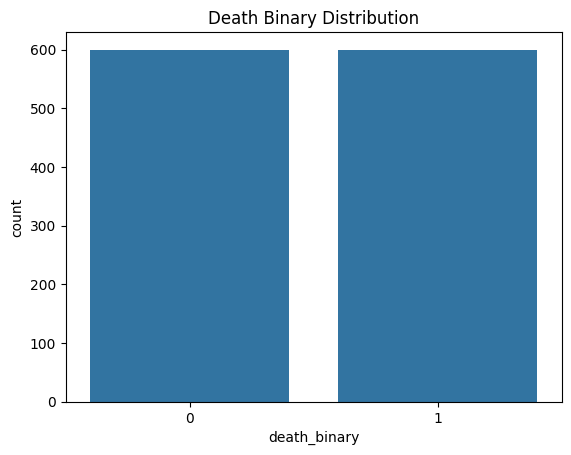

In [7]:
#사망률 분포
sns.countplot(x=df["death_binary"])
plt.title("Death Binary Distribution")
plt.show()


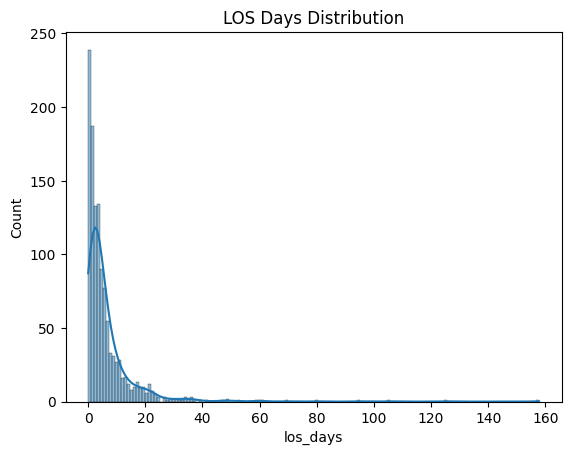

In [8]:
# 입원기간 분포
sns.histplot(df["los_days"], kde=True)
plt.title("LOS Days Distribution")
plt.show()


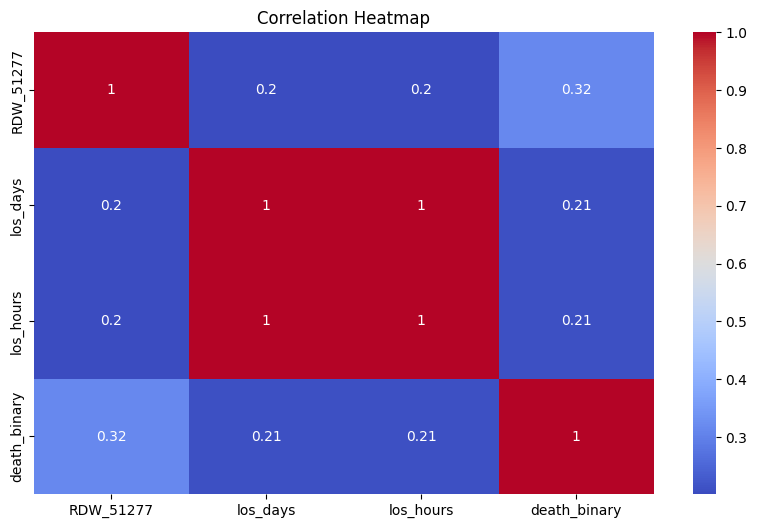

In [9]:
#상관관계 Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(df[["RDW_51277","los_days","los_hours","death_binary"]].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


In [10]:
#Feature(X) + Target(y) 준비
target = "death_binary"

y = df[target]
X = df.drop(columns=[target], errors="ignore")

# 숫자형만 유지
X = X.select_dtypes(include=["int64","float64","float32"])

#5. 데이터 분할 (Train / Test)

In [11]:
# 사망예측
y_death = y # Use the cleaned target from the overall split
X_death = X # Use the cleaned features from the overall split

X_train_d, X_test_d, y_train_d, y_test_d = train_test_split(
    X_death, y_death, test_size=0.2, random_state=713, stratify=y_death
)

print("Train:", X_train_d.shape, " Test:", X_test_d.shape)

Train: (960, 15)  Test: (240, 15)


In [12]:
#입원기간 예측

y_los = df["los_days"]
X_los = df.drop(["los_days","los_hours","death_binary"], axis=1)

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X_los, y_los, test_size=0.3, random_state=713
)

print("Train:", X_train_l.shape, " Test:", X_test_l.shape)

Train: (840, 3290)  Test: (360, 3290)


# Baseline 모델

#Logistic Regression

In [13]:
# Logistic Regression — 사망 예측 (분류)

# Identify non-numeric columns that cause error and drop them
non_numeric_cols = ['admittime', 'dischtime', 'deathtime', 'dod']

X_train_d_processed = X_train_d.drop(columns=non_numeric_cols, errors='ignore')
X_test_d_processed = X_test_d.drop(columns=non_numeric_cols, errors='ignore')

log_clf = LogisticRegression(max_iter=500)
log_clf.fit(X_train_d_processed, y_train_d)

pred_log_death = log_clf.predict(X_test_d_processed)
proba_log_death = log_clf.predict_proba(X_test_d_processed)[:,1]

print("Logistic Accuracy:", accuracy_score(y_test_d, pred_log_death))
print("Logistic AUC:", roc_auc_score(y_test_d, proba_log_death))

Logistic Accuracy: 0.65
Logistic AUC: 0.7278472222222222


In [14]:
# Logistic Regression — 입원기간 예측 (회귀)

# Identify non-numeric columns that cause error and drop them
# These steps are no longer needed as X_los from JWh4DGHr3zqe is already purely numeric
# non_numeric_cols = ['admittime', 'dischtime', 'deathtime', 'dod']
# X_train_l_processed = X_train_l.drop(columns=non_numeric_cols, errors='ignore')
# X_test_l_processed = X_test_l.drop(columns=non_numeric_cols, errors='ignore')

# Use the X_train_l and y_train_l directly from the latest split (JWh4DGHr3zqe)
lin_reg = LinearRegression()
lin_reg.fit(X_train_l, y_train_l)

# Use the X_test_l directly from the latest split (JWh4DGHr3zqe)
pred_lin = lin_reg.predict(X_test_l)

print("Linear RMSE:", np.sqrt(mean_squared_error(y_test_l, pred_lin)))
print("Linear R2:", r2_score(y_test_l, pred_lin))

Linear RMSE: 12.518829774708113
Linear R2: 0.10593132821914131




```
# This is formatted as code
```

#Random Forest 모델

In [15]:
#RF모델 - 사망예측 (분류)

# Identify non-numeric columns that cause error and drop them
non_numeric_cols = ['admittime', 'dischtime', 'deathtime', 'dod']

X_train_d_processed = X_train_d.drop(columns=non_numeric_cols, errors='ignore')
X_test_d_processed = X_test_d.drop(columns=non_numeric_cols, errors='ignore')

rf_clf = RandomForestClassifier(n_estimators=300, random_state=713)
rf_clf.fit(X_train_d_processed, y_train_d)

pred_rf = rf_clf.predict(X_test_d_processed)
proba_rf = rf_clf.predict_proba(X_test_d_processed)[:,1]

print("RF Accuracy:", accuracy_score(y_test_d, pred_rf))
print("RF AUC:", roc_auc_score(y_test_d, proba_rf))

RF Accuracy: 0.7708333333333334
RF AUC: 0.8649652777777778


In [16]:
#RF모델 - 입원기갼 예측 (회귀)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 1) Target log transform
y_train_log = np.log1p(y_train_l)
y_test_log = np.log1p(y_test_l)

# 2) Model
rf_reg = RandomForestRegressor(
    n_estimators=400,
    max_depth=None,
    min_samples_split=3,
    min_samples_leaf=2,
    random_state=713
)

rf_reg.fit(X_train_l, y_train_log)

# 3) Predict (log scale → revert)
pred_log = rf_reg.predict(X_test_l)
pred_rf_los = np.expm1(pred_log) # Renamed variable to pred_rf_los

# 4) Evaluation
rmse = np.sqrt(mean_squared_error(y_test_l, pred_rf_los)) # Use pred_rf_los
r2 = r2_score(y_test_l, pred_rf_los) # Use pred_rf_los

print("Improved RF RMSE:", rmse)
print("Improved RF R2:", r2)


Improved RF RMSE: 13.032845849859328
Improved RF R2: 0.031004129534839997


#XGBoost 모델

In [17]:
#XGB — 사망 예측

# Identify non-numeric columns that cause error and drop them
non_numeric_cols = ['admittime', 'dischtime', 'deathtime', 'dod']

X_train_d_processed = X_train_d.drop(columns=non_numeric_cols, errors='ignore')
X_test_d_processed = X_test_d.drop(columns=non_numeric_cols, errors='ignore')

xgb_clf = XGBClassifier(
    max_depth=4, learning_rate=0.05, n_estimators=300, subsample=0.8
)
xgb_clf.fit(X_train_d_processed, y_train_d)

pred_xgb = xgb_clf.predict(X_test_d_processed)
proba_xgb = xgb_clf.predict_proba(X_test_d_processed)[:,1]

print("XGB Accuracy:", accuracy_score(y_test_d, pred_xgb))
print("XGB AUC:", roc_auc_score(y_test_d, proba_xgb))

XGB Accuracy: 0.7583333333333333
XGB AUC: 0.8627777777777778


In [18]:
#XGB — 입원기간 예측 (회귀)

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd

# --------------------------
# 1) 범주형 변수 인코딩
# --------------------------
X_train_l_enc = pd.get_dummies(X_train_l, drop_first=True)
X_test_l_enc = pd.get_dummies(X_test_l, drop_first=True)

# 동일한 컬럼 맞추기
X_test_l_enc = X_test_l_enc.reindex(columns=X_train_l_enc.columns, fill_value=0)

# --------------------------
# 2) Target 로그 변환
# --------------------------
y_train_log = np.log1p(y_train_l)
y_test_log = np.log1p(y_test_l)

# --------------------------
# 3) 최적화된 XGBoost 모델
# --------------------------
xgb_reg = XGBRegressor(
    max_depth=6,
    learning_rate=0.03,
    n_estimators=500,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=2,
    reg_alpha=1,
    min_child_weight=5,
    random_state=713
)

xgb_reg.fit(X_train_l_enc, y_train_log)

# --------------------------
# 4) 예측 및 역변환
# --------------------------
pred_log_los = xgb_reg.predict(X_test_l_enc) # Renamed from pred_log
pred_xgb_los = np.expm1(pred_log_los)

# --------------------------
# 5) 평가
# --------------------------
rmse = np.sqrt(mean_squared_error(y_test_l, pred_xgb_los))
r2 = r2_score(y_test_l, pred_xgb_los)

print("🔥 Improved XGB RMSE:", rmse)
print("🔥 Improved XGB R2:", r2)


🔥 Improved XGB RMSE: 13.06441566432834
🔥 Improved XGB R2: 0.02630399405692052


# 9. SHAP 해석 (논문용 Feature Importance)
 XAI eXplaniable AI


Shape of rf_clf.feature_importances_ : (15,)
Number of features rf_clf was trained on (n_features_in_): 15
Shape of X_test_d_processed: (240, 15)
Shape of shap_values (raw output): (240, 15, 2)
Shape of shap_values[:, :, 1] (for class 1): (240, 15)


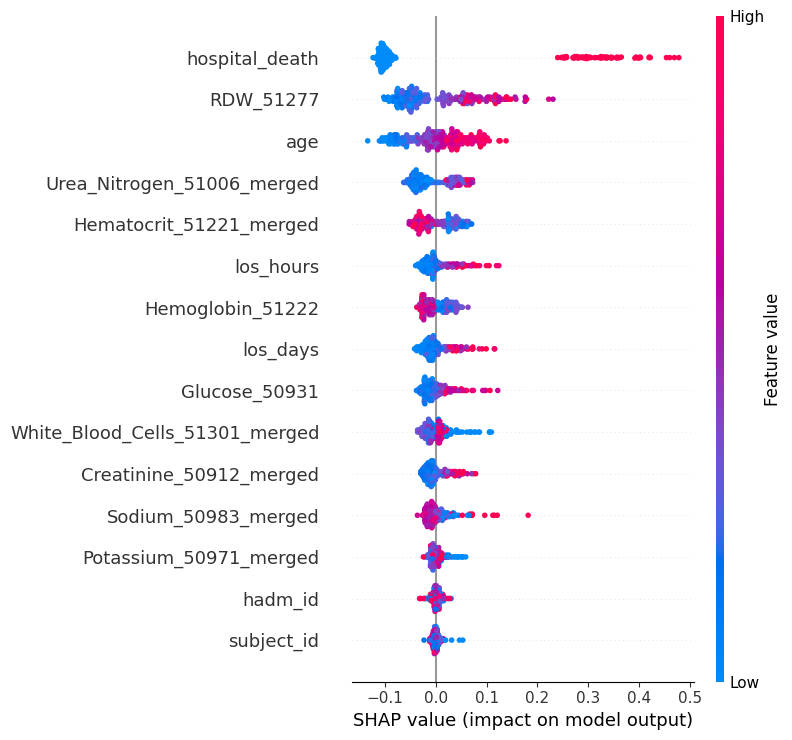

In [19]:
#RF에 대한 Shap  value
#SHAP > 0 → 해당 feature가 "사망 확률을 올린다"

explainer = shap.TreeExplainer(rf_clf)
shap_values = explainer.shap_values(X_test_d_processed)

print(f"Shape of rf_clf.feature_importances_ : {rf_clf.feature_importances_.shape}")
print(f"Number of features rf_clf was trained on (n_features_in_): {rf_clf.n_features_in_}")
print(f"Shape of X_test_d_processed: {X_test_d_processed.shape}")
print(f"Shape of shap_values (raw output): {shap_values.shape}")
print(f"Shape of shap_values[:, :, 1] (for class 1): {shap_values[:, :, 1].shape}")

shap.summary_plot(shap_values[:, :, 1], X_test_d_processed)

Shape of xgb_clf.feature_importances_ : (15,)
Number of features xgb_clf was trained on (n_features_in_): 15
Shape of X_test_d_processed: (240, 15)
Shape of shap_values (raw output): (240, 15)
Shape of shap_values (for positive class): (240, 15)


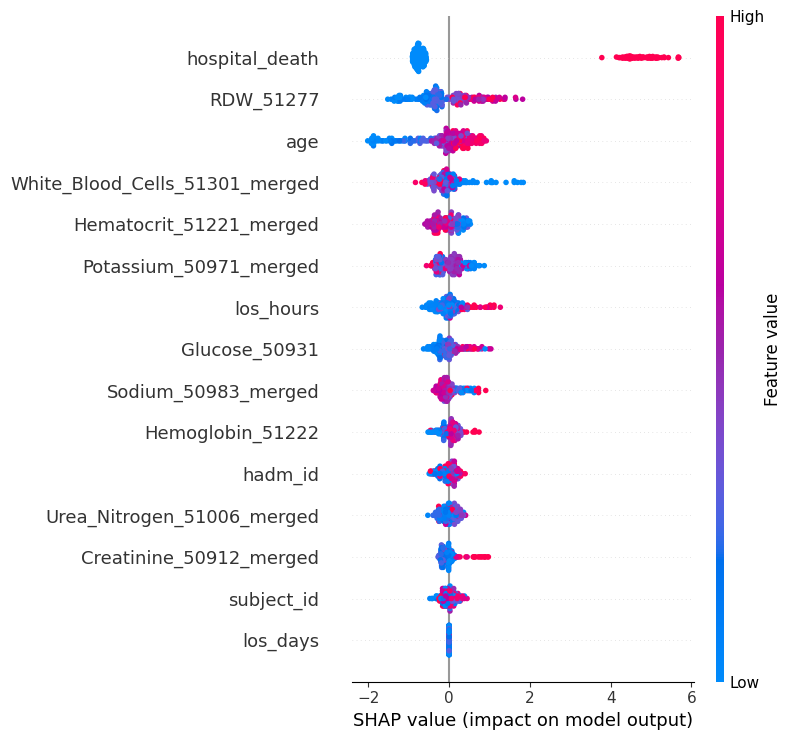

In [20]:
#XGBoost 에 대한 Shap  value
#SHAP > 0 → 해당 feature가 "사망 확률을 올린다"

explainer = shap.TreeExplainer(xgb_clf)
shap_values = explainer.shap_values(X_test_d_processed)

print(f"Shape of xgb_clf.feature_importances_ : {xgb_clf.feature_importances_.shape}")
print(f"Number of features xgb_clf was trained on (n_features_in_): {xgb_clf.n_features_in_}")
print(f"Shape of X_test_d_processed: {X_test_d_processed.shape}")
print(f"Shape of shap_values (raw output): {shap_values.shape}")
# Corrected line for 2D shap_values
print(f"Shape of shap_values (for positive class): {shap_values.shape}")

# Corrected line for summary_plot
shap.summary_plot(shap_values, X_test_d_processed)

In [21]:
death_results = pd.DataFrame({
    "Model": ["Logistic", "RandomForest", "XGBoost"],
    "Accuracy": [
        accuracy_score(y_test_d, pred_log_death), # Changed pred_log to pred_log_death
        accuracy_score(y_test_d, pred_rf),
        accuracy_score(y_test_d, pred_xgb)
    ],
    "AUC": [
        roc_auc_score(y_test_d, proba_log_death), # Changed proba_log to proba_log_death
        roc_auc_score(y_test_d, proba_rf),
        roc_auc_score(y_test_d, proba_xgb)
    ]
})

los_results = pd.DataFrame({
    "Model": ["LinearReg", "RF_Reg", "XGB_Reg"],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test_l, pred_lin)),
        np.sqrt(mean_squared_error(y_test_l, pred_rf_los)),
        np.sqrt(mean_squared_error(y_test_l, pred_xgb_los))
    ],
    "R2": [
        r2_score(y_test_l, pred_lin),
        r2_score(y_test_l, pred_rf_los),
        r2_score(y_test_l, pred_xgb_los)
    ]
})

death_results, los_results

(          Model  Accuracy       AUC
 0      Logistic  0.650000  0.727847
 1  RandomForest  0.770833  0.864965
 2       XGBoost  0.758333  0.862778,
        Model       RMSE        R2
 0  LinearReg  12.518830  0.105931
 1     RF_Reg  13.032846  0.031004
 2    XGB_Reg  13.064416  0.026304)

#AUROC 플롯 겹쳐서 그리기

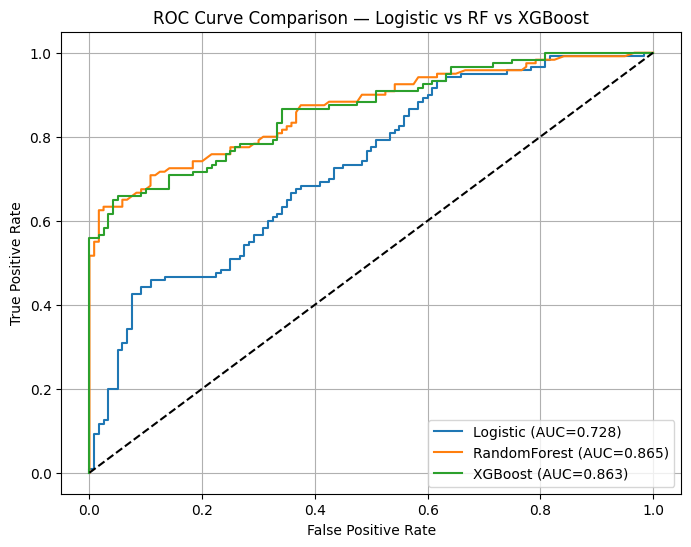

In [22]:
from sklearn.metrics import roc_curve

#사망예측에 대한 AUROC
plt.figure(figsize=(8, 6))

# Logistic
fpr_log, tpr_log, _ = roc_curve(y_test_d, proba_log_death)
plt.plot(fpr_log, tpr_log, label=f"Logistic (AUC={death_results['AUC'][0]:.3f})")

# RF
fpr_rf, tpr_rf, _ = roc_curve(y_test_d, proba_rf)
plt.plot(fpr_rf, tpr_rf, label=f"RandomForest (AUC={death_results['AUC'][1]:.3f})")

# XGB
fpr_xgb, tpr_xgb, _ = roc_curve(y_test_d, proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f"XGBoost (AUC={death_results['AUC'][2]:.3f})")

# baseline
plt.plot([0, 1], [0, 1], "k--")

plt.title("ROC Curve Comparison — Logistic vs RF vs XGBoost")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()
